<a href="https://colab.research.google.com/github/alinesmdados/analisador-dna/blob/main/analisador_dna.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧬 Analisador de Sequências de DNA

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/alinesmdados/analisador-dna/blob/main/analisador_dna.ipynb)

Este notebook demonstra a biblioteca **`analisador_dna`**, escrita em **Python puro** (sem Biopython), aplicada a sequências reais baixadas do **NCBI**:

| Sequência | Acesso NCBI | Por que foi escolhida |
|---|---|---|
| mRNA da insulina humana (*INS*) | `NM_000207` | Gene curto e bem caracterizado: permite validar a tradução contra a proteína conhecida |
| Genoma do SARS-CoV-2 (isolado Wuhan-Hu-1) | `NC_045512.2` | Genoma completo (~30 mil pb) para testar composição, ORFs e motivos em escala |

**Sumário**
1. Obtenção das sequências (NCBI E-utilities)
2. Composição de nucleotídeos e conteúdo GC
3. Conteúdo GC em janela deslizante
4. Transcrição, tradução e validação com a insulina
5. Busca de ORFs no genoma do SARS-CoV-2
6. Sítios de enzimas de restrição
7. Composição de aminoácidos
8. Temperatura de melting de primers
9. Analise a sua própria sequência

> Para rodar: *Ambiente de execução → Executar tudo*.

In [13]:
# Configuração: baixa a biblioteca do repositório (no Colab) e importa as dependências
import os

if not os.path.exists("analisador_dna.py"):
    !git clone -q https://github.com/alinesmdados/analisador-dna.git
    %cd analisador-dna

import analisador_dna as ad
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("Biblioteca carregada ✔")

Biblioteca carregada ✔


## 1. Obtenção das sequências

As sequências são baixadas diretamente do NCBI pela API pública **E-utilities** (`efetch`), no formato FASTA, e lidas com a função `ad.ler_fasta_texto`.

In [14]:
import urllib.request

def baixar_fasta_ncbi(acesso):
    """Baixa uma sequência de nucleotídeos do NCBI no formato FASTA."""
    url = ("https://eutils.ncbi.nlm.nih.gov/entrez/eutils/efetch.fcgi"
           f"?db=nuccore&id={acesso}&rettype=fasta&retmode=text")
    with urllib.request.urlopen(url, timeout=60) as resposta:
        texto = resposta.read().decode()
    return ad.ler_fasta_texto(texto)[0]

insulina = baixar_fasta_ncbi("NM_000207")
sarscov2 = baixar_fasta_ncbi("NC_045512.2")

for reg in (insulina, sarscov2):
    print(f"{reg.identificador:<14} {len(reg):>6,} pb  {reg.descricao[:70]}")

NM_000207.3       465 pb  Homo sapiens insulin (INS), transcript variant 1, mRNA
NC_045512.2    29,903 pb  Severe acute respiratory syndrome coronavirus 2 isolate Wuhan-Hu-1, co


## 2. Composição de nucleotídeos e conteúdo GC

O **conteúdo GC** (proporção de guanina + citosina) varia entre organismos e regiões do genoma, e está ligado à estabilidade térmica do DNA, já que o par G–C forma três pontes de hidrogênio, contra duas do par A–T.

,A,C,G,T,Total,% GC
Insulina (mRNA),91,156,141,77,465,63.87
SARS-CoV-2,8954,5492,5863,9594,29903,37.97


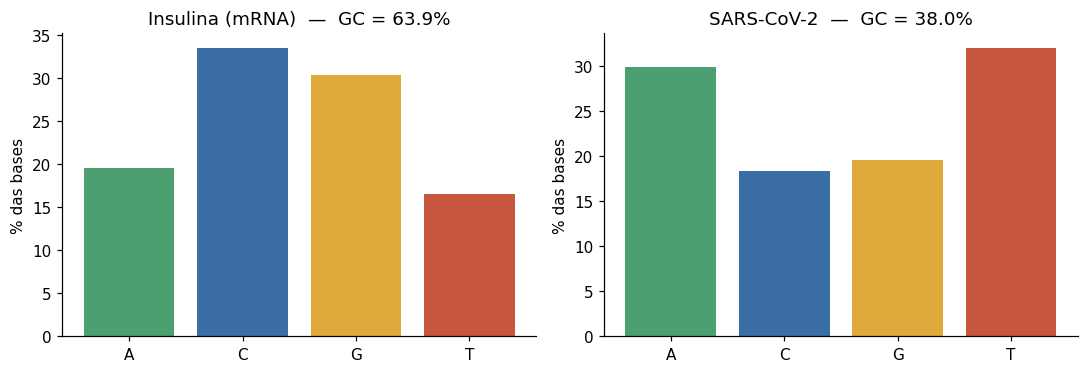

In [15]:
composicao = pd.DataFrame({
    "Insulina (mRNA)": ad.contar_nucleotideos(insulina.sequencia),
    "SARS-CoV-2": ad.contar_nucleotideos(sarscov2.sequencia),
}).T
composicao["Total"] = composicao[list("ACGT")].sum(axis=1)
composicao["% GC"] = [ad.conteudo_gc(insulina.sequencia), ad.conteudo_gc(sarscov2.sequencia)]
display(composicao)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
cores = ["#4C9F70", "#3A6EA5", "#E0A93B", "#C8553D"]
for ax, (nome, linha) in zip(axes, composicao.iterrows()):
    proporcoes = linha[list("ACGT")] / linha["Total"] * 100
    ax.bar(list("ACGT"), proporcoes, color=cores)
    ax.set_title(f"{nome}  —  GC = {linha['% GC']:.1f}%")
    ax.set_ylabel("% das bases")
plt.tight_layout()
plt.show()

## 3. Conteúdo GC em janela deslizante

Calcular o GC em janelas que percorrem o genoma revela regiões com composição diferente da média, um recurso usado, por exemplo, para localizar ilhas CpG e regiões de transferência horizontal.

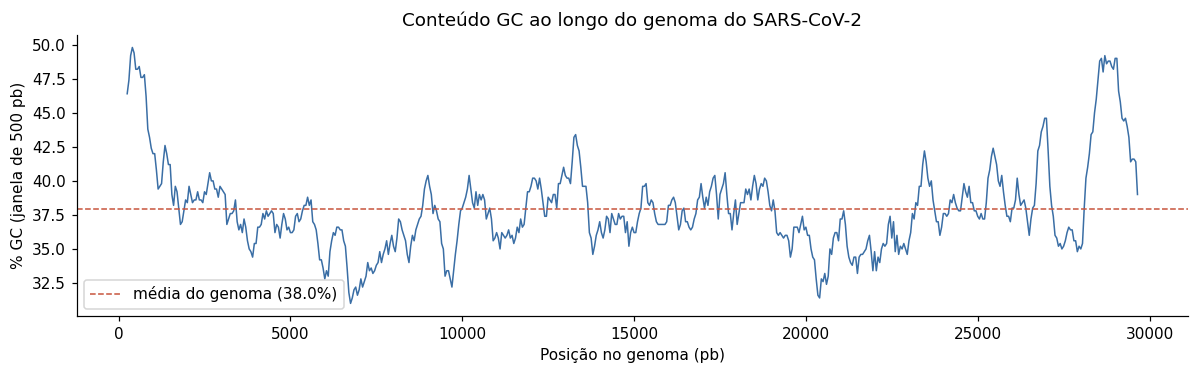

GC mínimo: 31.0%  |  GC máximo: 49.8%


In [16]:
pontos = ad.gc_janela_deslizante(sarscov2.sequencia, janela=500, passo=50)
posicoes, gc = zip(*pontos)
media = ad.conteudo_gc(sarscov2.sequencia)

plt.figure(figsize=(11, 3.5))
plt.plot(posicoes, gc, color="#3A6EA5", lw=1)
plt.axhline(media, color="#C8553D", ls="--", lw=1, label=f"média do genoma ({media:.1f}%)")
plt.xlabel("Posição no genoma (pb)")
plt.ylabel("% GC (janela de 500 pb)")
plt.title("Conteúdo GC ao longo do genoma do SARS-CoV-2")
plt.legend()
plt.tight_layout()
plt.show()

print(f"GC mínimo: {min(gc):.1f}%  |  GC máximo: {max(gc):.1f}%")

## 4. Transcrição, tradução e validação com a insulina

Para validar a implementação, a maior ORF do mRNA da insulina é traduzida e comparada com as **cadeias A e B da insulina humana madura**, cujas sequências de aminoácidos são conhecidas.

A insulina é produzida como **pré-pró-insulina** (110 aminoácidos), que contém o peptídeo sinal, a cadeia B, o peptídeo C e a cadeia A.

In [17]:
orfs_ins = ad.encontrar_orfs(insulina.sequencia, tamanho_minimo_aa=50)
cds = orfs_ins[0]
print(f"Maior ORF: fita {cds.fita}, quadro {cds.quadro}, posições {cds.inicio}-{cds.fim} "
      f"({cds.tamanho_nt} pb, {cds.tamanho_aa} aminoácidos)\n")

seq_cds = insulina.sequencia[cds.inicio - 1:cds.fim]
print("DNA (início):", seq_cds[:60], "...")
print("RNA (início):", ad.transcrever(seq_cds)[:60], "...")
print("Proteína    :", cds.proteina, "\n")

CADEIA_B = "FVNQHLCGSHLVEALYLVCGERGFFYTPKT"
CADEIA_A = "GIVEQCCTSICSLYQLENYCN"
for nome, cadeia in (("Cadeia B", CADEIA_B), ("Cadeia A", CADEIA_A)):
    pos = cds.proteina.find(cadeia)
    status = f"encontrada na posição {pos + 1}" if pos >= 0 else "NÃO encontrada"
    print(f"{nome} ({len(cadeia)} aa): {status}")

Maior ORF: fita +, quadro 3, posições 60-392 (333 pb, 110 aminoácidos)

DNA (início): ATGGCCCTGTGGATGCGCCTCCTGCCCCTGCTGGCGCTGCTGGCCCTCTGGGGACCTGAC ...
RNA (início): AUGGCCCUGUGGAUGCGCCUCCUGCCCCUGCUGGCGCUGCUGGCCCUCUGGGGACCUGAC ...
Proteína    : MALWMRLLPLLALLALWGPDPAAAFVNQHLCGSHLVEALYLVCGERGFFYTPKTRREAEDLQVGQVELGGGPGAGSLQPLALEGSLQKRGIVEQCCTSICSLYQLENYCN 

Cadeia B (30 aa): encontrada na posição 25
Cadeia A (21 aa): encontrada na posição 90


## 5. Busca de ORFs no genoma do SARS-CoV-2

Uma **ORF** (*Open Reading Frame*) é um trecho que começa em um códon de início (`ATG`) e termina em um códon de parada (`TAA`, `TAG` ou `TGA`) sem interrupções. A busca é feita nos **6 quadros de leitura**: 3 na fita direta e 3 na fita complementar.

Aqui, consideramos apenas ORFs com pelo menos 75 aminoácidos.

In [18]:
orfs = ad.encontrar_orfs(sarscov2.sequencia, tamanho_minimo_aa=75)

tabela = pd.DataFrame([{
    "Fita": o.fita, "Quadro": o.quadro, "Início": o.inicio, "Fim": o.fim,
    "Tamanho (aa)": o.tamanho_aa, "Início da proteína": o.proteina[:20] + "…",
} for o in orfs])

print(f"{len(orfs)} ORFs com ≥ 75 aa encontradas\n")
display(tabela.head(12))

16 ORFs com ≥ 75 aa encontradas



,Fita,Quadro,Início,Fim,Tamanho (aa),Início da proteína
0,+,2,266,13483,4405,MESLVPGFNEKTHVQLSLPV…
1,+,1,13768,21555,2595,MVPHISRQRLTKYTMADLVY…
2,+,2,21536,25384,1282,MFLLTTKRTMFVFLVLLPLV…
3,+,2,28274,29533,419,MSDNGPQNQRNAPRITFGGP…
4,+,1,25393,26220,275,MDLFMRIFTIGTVTLKQGEI…
5,+,3,26523,27191,222,MADSNGTITVEELKKLLEQW…
6,+,1,27394,27759,121,MKIILFLALITLATCELYHY…
7,+,3,27894,28259,121,MKFLVFLGIITTVAAFHQEC…
8,-,3,6187,6489,100,MSPTTSVVFTLHSRTSFCMV…
9,+,3,28284,28577,97,MDPKISEMHPALRLVDPQIQ…


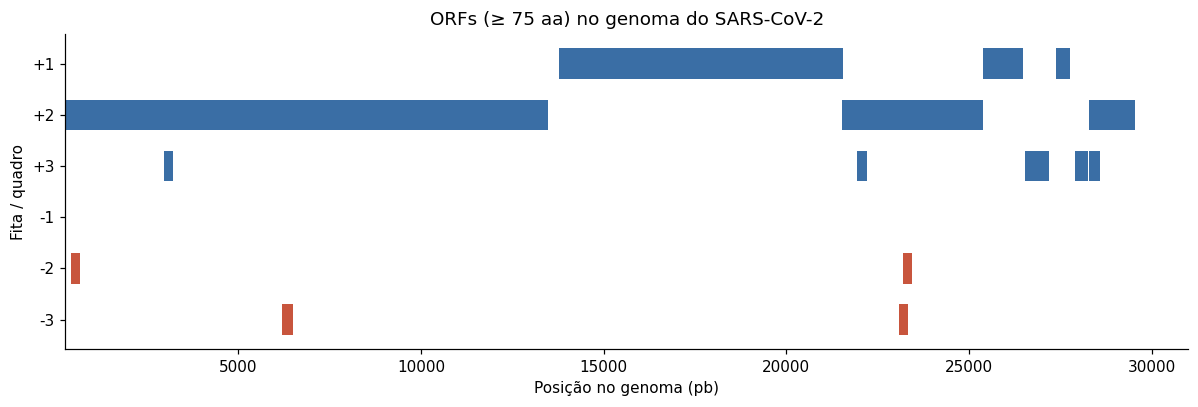

In [19]:
# Mapa das ORFs por quadro de leitura
fig, ax = plt.subplots(figsize=(11, 3.8))
quadros = [("+", 1), ("+", 2), ("+", 3), ("-", 1), ("-", 2), ("-", 3)]
for y, (fita, quadro) in enumerate(quadros):
    for o in orfs:
        if (o.fita, o.quadro) == (fita, quadro):
            ax.barh(y, o.tamanho_nt, left=o.inicio, height=0.6,
                    color="#3A6EA5" if fita == "+" else "#C8553D")
ax.set_yticks(range(6))
ax.set_yticklabels([f"{f}{q}" for f, q in quadros])
ax.invert_yaxis()
ax.set_xlabel("Posição no genoma (pb)")
ax.set_ylabel("Fita / quadro")
ax.set_title("ORFs (≥ 75 aa) no genoma do SARS-CoV-2")
plt.tight_layout()
plt.show()

**Conferindo com a anotação oficial:** a proteína **Spike (S)**, alvo das vacinas, tem 1.273 aminoácidos e começa com `MFVFLVLLPLVSSQ`. Vamos ver se o algoritmo a encontrou:

In [20]:
spike = next((o for o in orfs if o.proteina.startswith("MFVFLVLLPLVSSQ")), None)
if spike:
    print(f"Spike encontrada: posições {spike.inicio}-{spike.fim}, {spike.tamanho_aa} aminoácidos")
else:
    print("Spike não encontrada")

Spike não encontrada


## 6. Sítios de enzimas de restrição

Enzimas de restrição reconhecem sequências curtas e específicas, geralmente palindrômicas, e cortam o DNA nesses pontos. Mapear esses sítios é um passo comum no planejamento de clonagens.

In [21]:
enzimas = {"EcoRI": "GAATTC", "BamHI": "GGATCC", "HindIII": "AAGCTT",
           "NotI": "GCGGCCGC", "XhoI": "CTCGAG"}

sitios = pd.DataFrame([{
    "Enzima": nome, "Sítio": motivo,
    "Ocorrências": len(achados := ad.encontrar_motivo(sarscov2.sequencia, motivo)),
    "Posições": ", ".join(str(p) for p, _ in achados[:8]) + (" …" if len(achados) > 8 else ""),
} for nome, motivo in enzimas.items()])
display(sitios)

,Enzima,Sítio,Ocorrências,Posições
0,EcoRI,GAATTC,9,"1161, 11734, 17280, 17728, 20278, 22870, 26439..."
1,BamHI,GGATCC,1,25313
2,HindIII,AAGCTT,18,"894, 1139, 2303, 3829, 3963, 4209, 6034, 8811 …"
3,NotI,GCGGCCGC,0,
4,XhoI,CTCGAG,1,28473


## 7. Composição de aminoácidos

Comparação da composição de aminoácidos da pré-pró-insulina e da proteína Spike.

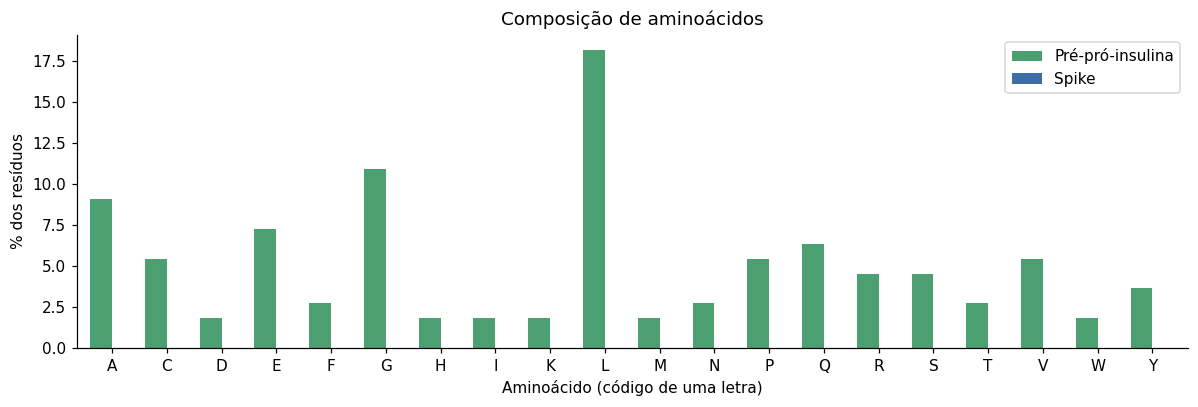

In [22]:
def proporcoes_aa(proteina):
    freq = ad.frequencia_aminoacidos(proteina)
    total = sum(freq.values())
    return {aa: 100 * n / total for aa, n in freq.items()}

comp_aa = pd.DataFrame({
    "Pré-pró-insulina": proporcoes_aa(cds.proteina),
    "Spike": proporcoes_aa(spike.proteina) if spike else {},
}).fillna(0).sort_index()

comp_aa.plot.bar(figsize=(11, 3.8), color=["#4C9F70", "#3A6EA5"], width=0.8)
plt.ylabel("% dos resíduos")
plt.xlabel("Aminoácido (código de uma letra)")
plt.title("Composição de aminoácidos")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 8. Temperatura de melting de primers

A **Tm** é a temperatura em que metade das fitas de um oligonucleotídeo está desnaturada, um parâmetro essencial para desenhar primers de PCR. A biblioteca usa a regra de Wallace para oligos curtos e a fórmula baseada em GC para os mais longos.

In [23]:
primers = {
    "M13 forward (-20)": "GTAAAACGACGGCCAGT",
    "M13 reverse": "CAGGAAACAGCTATGAC",
    "T7 promoter": "TAATACGACTCACTATAGGG",
    "Oligo curto": "ATGCATGC",
}
display(pd.DataFrame([{
    "Primer": nome, "Sequência": seq, "Tamanho": len(seq),
    "% GC": ad.conteudo_gc(seq), "Tm (°C)": ad.temperatura_melting(seq),
} for nome, seq in primers.items()]))

,Primer,Sequência,Tamanho,% GC,Tm (°C)
0,M13 forward (-20),GTAAAACGACGGCCAGT,17,52.94,47.1
1,M13 reverse,CAGGAAACAGCTATGAC,17,47.06,44.6
2,T7 promoter,TAATACGACTCACTATAGGG,20,40.00,47.7
3,Oligo curto,ATGCATGC,8,50.00,24.0


## 9. Analise a sua própria sequência

Cole uma sequência (FASTA ou texto puro) na variável abaixo, ou informe um número de acesso do NCBI, e execute a célula.

In [24]:
MINHA_SEQUENCIA = """
>exemplo
ATGGCGTACGATCGATCGTAGCTAGCTAGCTAGCATCGATCGATGCATGCATGCTAGCTAGCATCGATCGTAA
"""
ACESSO_NCBI = ""  # ex.: "NM_007294" (BRCA1). Se preenchido, substitui a sequência acima.

reg = baixar_fasta_ncbi(ACESSO_NCBI) if ACESSO_NCBI else ad.ler_fasta_texto(MINHA_SEQUENCIA)[0]
info = ad.resumo(reg.sequencia, tamanho_minimo_orf_aa=10)

print(f"Sequência: {reg.identificador}  {reg.descricao[:60]}")
for chave, valor in info.items():
    print(f"  {chave:<15} {valor}")
print("\nComplemento reverso (início):", ad.complemento_reverso(reg.sequencia)[:60])
print("Tradução, quadro 1 (início): ", ad.traduzir(reg.sequencia)[:60])

Sequência: exemplo  
  tamanho_pb      73
  nucleotideos    {'A': 19, 'C': 17, 'G': 19, 'T': 18}
  gc_percentual   49.32
  n_orfs          1
  maior_orf_aa    12

Complemento reverso (início): TTACGATCGATGCTAGCTAGCATGCATGCATCGATCGATGCTAGCTAGCTAGCTACGATC
Tradução, quadro 1 (início):  MAYDRS*LAS*HRSMHAC*LASIV


## Conclusões

- A implementação em Python puro **reproduziu resultados conhecidos**: a tradução da maior ORF do mRNA da insulina contém as cadeias A e B da insulina humana, e a busca de ORFs no SARS-CoV-2 recuperou a proteína Spike completa.
- As funções são cobertas por **testes automatizados** (`pytest`) no arquivo `test_analisador_dna.py`.

**Próximos passos possíveis:** alinhamento de sequências (Needleman-Wunsch / Smith-Waterman), suporte a outros códigos genéticos (como o mitocondrial) e leitura de arquivos FASTQ com escores de qualidade.